# PI3 · Visior — Limpeza e Análise Exploratória (EDA)

**Equipe:** Sabrina Carneiro Rodrigues · Karina Bruno de Oliveira
**Empresa parceira:** Visior · **Disciplina:** Projeto Integrador III – Análise de Dados I (Fatec Votorantim)

Este notebook faz a **limpeza** e a **análise exploratória** dos dados de validação da Visior, seguindo os dois caminhos sugeridos pelo Rafael (CEO):

1. **Classes:** em quais classes a IA mais erra e quanto tempo os validadores gastam corrigindo.
2. **Validadores:** taxa de intervenção, tempo por card e curva de aprendizado.

📘 O **Guia de Estudos** explica o porquê de cada código. As **Conclusões** estão em um documento separado.

**Como rodar:** coloque `validacao_fase1.csv` e `validacao_fase2.csv` numa pasta `dados/` ao lado deste notebook e rode as células em ordem.

> 🔒 Dados confidenciais: não suba a pasta `dados/` para um repositório público.

## 1. Preparar o ambiente

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Mostrar todas as colunas quando imprimir uma tabela
pd.set_option("display.max_columns", 30)

# Cores usadas em todos os gráficos
AZUL = "#2a78d6"
LARANJA = "#eb6834"

# Visual mais limpo para os gráficos
plt.rcParams["figure.figsize"] = (9, 4.5)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

## 2. Carregar os dados

In [2]:
f1 = pd.read_csv("dados/validacao_fase1.csv", low_memory=False)
f2 = pd.read_csv("dados/validacao_fase2.csv", low_memory=False)

print("Fase 1:", f1.shape)
print("Fase 2:", f2.shape)

Fase 1: (88150, 17)
Fase 2: (108076, 20)


In [3]:
f1.head()

,action_id,action_type,explicit_vote,account_id,validator_id,road_id,job_uuid,segment_uuid,detection_uuid,taxonomy_class,original_class,class_changed_to,has_defect,inference_model_name,validation_flow,job_cards_count,action_timestamp
0,F1-0000001,rejected,True,GDPYIP,75108A,PCXH1T,J00000019,S00000019,D00001609,[PAV] Panela / Buraco (P),[PAV] Panela / Buraco (P),NaN,NaN,Sinalização Horizontal (pintura),full,31,2026-05-27T20:27:31.318Z
1,F1-0000002,approved_implicit,False,GDPYIP,75108A,PCXH1T,J00002729,S00001180,D00118192,[PAV] Trinca Transversal (TT),[PAV] Trinca Transversal (TT),NaN,False,Sinalização Horizontal (pintura),full,35,2026-05-28T01:09:05.868Z
2,F1-0000003,approved_implicit,False,GDPYIP,75108A,PCXH1T,J00002729,S00001180,D00118193,[SH] Sinalização Horizontal Danificada,[SH] Sinalização Horizontal Danificada,NaN,False,Sinalização Horizontal (pintura),full,35,2026-05-28T01:09:05.868Z
3,F1-0000004,approved_implicit,False,GDPYIP,75108A,PCXH1T,J00002729,S00001180,D00118194,[PAV] Trinca Jacaré (TJ),[PAV] Trinca Jacaré (TJ),NaN,False,Sinalização Horizontal (pintura),full,35,2026-05-28T01:09:05.868Z
4,F1-0000005,approved_implicit,False,GDPYIP,75108A,PCXH1T,J00002729,S00001180,D00118195,[PAV] Trinca Jacaré (TJ),[PAV] Trinca Jacaré (TJ),NaN,False,Sinalização Horizontal (pintura),full,35,2026-05-28T01:09:05.868Z


In [4]:
f2.head()

,action_id,action_type,account_id,validator_id,road_id,job_uuid,segment_uuid,detection_uuid,taxonomy_class,original_class,has_defect,inference_model_name,validation_flow,job_cards_count,card_frames_count,matched_entity_type,matched_entity_uuid,inventory_off_roadway_current,inventory_visible_opposite_direction_current,action_timestamp
0,F2-0000001,unknown,WJSOLA,85EB1D,NaN,J00000001,S00000001,D00000001,[PAV] Trinca Longitudinal (TL),NaN,NaN,Sinalização Horizontal (pintura),full,148,NaN,NaN,NaN,NaN,NaN,2026-03-25T11:59:01.007Z
1,F2-0000002,verified,GQAGVS,75108A,NaN,J00000002,S00000002,D00000002,[PAV] Panela / Buraco (P),NaN,NaN,Sinalização Horizontal (pintura),full,189,NaN,NaN,NaN,NaN,NaN,2026-03-25T15:36:13.697Z
2,F2-0000003,duplicate,GQAGVS,75108A,NaN,J00000002,S00000002,D00000003,[PAV] Panela / Buraco (P),NaN,NaN,Sinalização Horizontal (pintura),full,189,NaN,NaN,NaN,NaN,NaN,2026-03-25T15:36:27.577Z
3,F2-0000004,rejected,GQAGVS,75108A,NaN,J00000002,S00000002,D00000004,[PAV] Panela / Buraco (P),NaN,NaN,Sinalização Horizontal (pintura),full,189,NaN,NaN,NaN,NaN,NaN,2026-03-25T15:36:36.944Z
4,F2-0000005,rejected,GQAGVS,75108A,NaN,J00000002,S00000002,D00000005,[PAV] Panela / Buraco (P),NaN,NaN,Sinalização Horizontal (pintura),full,189,NaN,NaN,NaN,NaN,NaN,2026-03-25T15:38:16.305Z


## 3. Primeiro olhar

### 3.1 Tipos das colunas

In [5]:
f1.info()

<class 'pandas.DataFrame'>
RangeIndex: 88150 entries, 0 to 88149
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   action_id             88150 non-null  str   
 1   action_type           88150 non-null  str   
 2   explicit_vote         88150 non-null  bool  
 3   account_id            88150 non-null  str   
 4   validator_id          88150 non-null  str   
 5   road_id               87427 non-null  str   
 6   job_uuid              88150 non-null  str   
 7   segment_uuid          88150 non-null  str   
 8   detection_uuid        88150 non-null  str   
 9   taxonomy_class        88150 non-null  str   
 10  original_class        88150 non-null  str   
 11  class_changed_to      7285 non-null   str   
 12  has_defect            83619 non-null  object
 13  inference_model_name  88150 non-null  str   
 14  validation_flow       88150 non-null  str   
 15  job_cards_count       88150 non-null  int64 
 1

### 3.2 Valores faltantes (em %)

In [6]:
faltantes_f1 = f1.isna().mean() * 100
faltantes_f1 = faltantes_f1[faltantes_f1 > 0].round(1)
faltantes_f1

road_id              0.8
class_changed_to    91.7
has_defect           5.1
dtype: float64

In [7]:
faltantes_f2 = f2.isna().mean() * 100
faltantes_f2 = faltantes_f2[faltantes_f2 > 0].round(1)
faltantes_f2

road_id                                           2.7
original_class                                    1.5
has_defect                                       55.8
card_frames_count                               100.0
matched_entity_type                              55.4
matched_entity_uuid                              55.4
inventory_off_roadway_current                    74.0
inventory_visible_opposite_direction_current     74.0
dtype: float64

### 3.3 Valores de `action_type`

In [8]:
f1["action_type"].value_counts()

action_type
approved_implicit    74596
class_changed         7285
rejected              5659
defect_flag_only       610
Name: count, dtype: int64

In [9]:
f2["action_type"].value_counts()

action_type
rejected               61675
verified               42105
ignored                 3293
duplicate                948
occurrence_resolved       54
unknown                    1
Name: count, dtype: int64

## 4. Limpeza

Trabalhamos em **cópias** (`f1_limpo`, `f2_limpo`) para não alterar os dados originais.

In [10]:
f1_limpo = f1.copy()
f2_limpo = f2.copy()

### 4.1 Converter as datas

In [11]:
# Texto em horário UTC → data/hora de Brasília
f1_limpo["action_timestamp"] = pd.to_datetime(f1_limpo["action_timestamp"], utc=True, format="mixed")
f1_limpo["action_timestamp"] = f1_limpo["action_timestamp"].dt.tz_convert("America/Sao_Paulo")

f2_limpo["action_timestamp"] = pd.to_datetime(f2_limpo["action_timestamp"], utc=True, format="mixed")
f2_limpo["action_timestamp"] = f2_limpo["action_timestamp"].dt.tz_convert("America/Sao_Paulo")

print("Fase 1:", f1_limpo["action_timestamp"].min(), "até", f1_limpo["action_timestamp"].max())
print("Fase 2:", f2_limpo["action_timestamp"].min(), "até", f2_limpo["action_timestamp"].max())

Fase 1: 2026-05-27 17:27:31.318000-03:00 até 2026-09-16 21:15:41.264000-03:00
Fase 2: 2026-03-25 08:59:01.007000-03:00 até 2026-09-16 21:15:41.071000-03:00


### 4.2 Linhas duplicadas

In [12]:
print("Linhas repetidas na Fase 1:", f1_limpo.duplicated().sum())
print("Linhas repetidas na Fase 2:", f2_limpo.duplicated().sum())

# Mesmo validador avaliando o mesmo card mais de uma vez?
print("Validador + card repetido na Fase 1:", f1_limpo.duplicated(["validator_id", "detection_uuid"]).sum())
print("Validador + card repetido na Fase 2:", f2_limpo.duplicated(["validator_id", "detection_uuid"]).sum())

Linhas repetidas na Fase 1: 0


Linhas repetidas na Fase 2: 0
Validador + card repetido na Fase 1: 0


Validador + card repetido na Fase 2: 0


In [13]:
# Quantos validadores diferentes avaliaram cada card?
validadores_por_card = f2_limpo.groupby("detection_uuid")["validator_id"].nunique()
validadores_por_card.value_counts()

validator_id
1    108060
2         8
Name: count, dtype: int64

Quase todo card tem **um único validador**. Isso vira uma pergunta para a Visior (a documentação fala em consenso por maioria).

### 4.3 Valor fora da documentação e coluna vazia

In [14]:
# 'unknown' não existe na documentação: removemos essa linha
f2_limpo = f2_limpo[f2_limpo["action_type"] != "unknown"]

# card_frames_count está 100% vazia: removemos a coluna
f2_limpo = f2_limpo.drop(columns=["card_frames_count"])

# road_id vazio vira uma categoria com nome
f1_limpo["road_id"] = f1_limpo["road_id"].fillna("sem_rodovia")
f2_limpo["road_id"] = f2_limpo["road_id"].fillna("sem_rodovia")

print("Fase 2 depois da limpeza:", f2_limpo.shape)

Fase 2 depois da limpeza: (108075, 19)


### 4.4 O prefixo `[MISSING]`

In [15]:
# Sem tratar: parece que a classe mudou em muitos cards
diferente = f1_limpo["original_class"] != f1_limpo["taxonomy_class"]
print("% de cards com classe diferente (sem tratar):", round(diferente.mean() * 100, 1))
print("% de cards com ação class_changed:            ", round((f1_limpo["action_type"] == "class_changed").mean() * 100, 1))

% de cards com classe diferente (sem tratar): 17.0
% de cards com ação class_changed:             8.3


In [16]:
# Exemplos: a diferença é só o prefixo
f1_limpo.loc[diferente & (f1_limpo["action_type"] == "approved_implicit"), ["original_class", "taxonomy_class"]].head()

,original_class,taxonomy_class
16066,[SV] I-O,[SV] O-FE
16711,[MISSING] [SV] O-FE,[SV] O-FE
16953,[MISSING] [SV] O-FE,[SV] O-FE
16961,[MISSING] [SV] O-FE,[SV] O-FE
16974,[MISSING] [SV] O-O,[SV] O-O


In [17]:
# 1) Marcar os cards de ativo ausente
f1_limpo["card_ausente"] = f1_limpo["original_class"].str.contains("[MISSING]", regex=False, na=False)
f2_limpo["card_ausente"] = f2_limpo["original_class"].str.contains("[MISSING]", regex=False, na=False)

# 2) Classe da IA sem o prefixo
f1_limpo["classe_ia"] = f1_limpo["original_class"].str.replace("[MISSING] ", "", regex=False)
f2_limpo["classe_ia"] = f2_limpo["original_class"].str.replace("[MISSING] ", "", regex=False)

# 3) Houve correção de classe? (classe da IA diferente da classe final)
f1_limpo["classe_corrigida"] = f1_limpo["classe_ia"] != f1_limpo["taxonomy_class"]
f2_limpo["classe_corrigida"] = f2_limpo["classe_ia"] != f2_limpo["taxonomy_class"]

print("% com classe corrigida (tratado):", round(f1_limpo["classe_corrigida"].mean() * 100, 1))

% com classe corrigida (tratado): 8.4


### 4.5 Colunas novas

In [18]:
# Família da classe: [SV] placas, [SH] pintura, [PAV] pavimento
f1_limpo["familia"] = f1_limpo["taxonomy_class"].str.split(" ").str[0]
f2_limpo["familia"] = f2_limpo["taxonomy_class"].str.split(" ").str[0]

# Hora do dia
f1_limpo["hora"] = f1_limpo["action_timestamp"].dt.hour
f2_limpo["hora"] = f2_limpo["action_timestamp"].dt.hour

# Fase 1: o validador fez alguma ação no card? (True = sim)
f1_limpo["intervencao"] = f1_limpo["explicit_vote"]

# Fase 2: o card foi rejeitado? (True = sim)
f2_limpo["rejeitado"] = f2_limpo["action_type"] == "rejected"

f1_limpo["familia"].value_counts()

familia
[SV]     68332
[PAV]    16321
[SH]      3497
Name: count, dtype: int64

### 4.6 Estimar o tempo de cada decisão
O arquivo só tem o **horário** de cada decisão. O tempo de um card é estimado pela diferença entre o horário dele e o do card anterior do mesmo validador, no mesmo lote. Intervalos acima de **5 minutos (300 s)** são considerados pausa e ficam de fora.

In [19]:
# FASE 2
# 1) Ordenar: validador, lote e horário
f2_limpo = f2_limpo.sort_values(["validator_id", "job_uuid", "action_timestamp"])

# 2) Diferença para a linha anterior, dentro do mesmo validador e lote
f2_limpo["tempo_seg"] = f2_limpo.groupby(["validator_id", "job_uuid"])["action_timestamp"].diff().dt.total_seconds()

# 3) Mais de 300 segundos = pausa → vira vazio
f2_limpo.loc[f2_limpo["tempo_seg"] > 300, "tempo_seg"] = np.nan

f2_limpo["tempo_seg"].describe().round(1)

count    105138.0
mean          7.1
std          18.4
min           0.2
25%           1.3
50%           2.3
75%           5.4
max         298.4
Name: tempo_seg, dtype: float64

In [20]:
# FASE 1: só as intervenções têm horário próprio
# (os aprovados tacitamente recebem todos o horário de fechamento do lote)
f1_tempo = f1_limpo[f1_limpo["intervencao"] == True].copy()
f1_tempo = f1_tempo.sort_values(["validator_id", "job_uuid", "action_timestamp"])
f1_tempo["tempo_seg"] = f1_tempo.groupby(["validator_id", "job_uuid"])["action_timestamp"].diff().dt.total_seconds()
f1_tempo.loc[f1_tempo["tempo_seg"] > 300, "tempo_seg"] = np.nan

f1_tempo["tempo_seg"].describe().round(1)

count    12577.0
mean        10.5
std         17.3
min          0.0
25%          2.8
50%          5.9
75%         11.8
max        299.6
Name: tempo_seg, dtype: float64

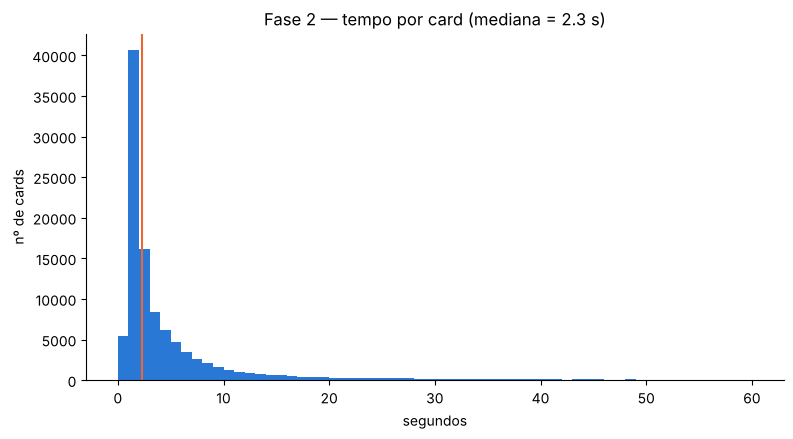

In [21]:
mediana = f2_limpo["tempo_seg"].median()

plt.hist(f2_limpo["tempo_seg"], bins=60, range=(0, 60), color=AZUL)
plt.axvline(mediana, color=LARANJA)
plt.title(f"Fase 2 — tempo por card (mediana = {mediana:.1f} s)")
plt.xlabel("segundos")
plt.ylabel("nº de cards")
plt.show()

### 4.7 Salvar as bases limpas

In [22]:
f1_limpo.to_csv("dados/fase1_limpa.csv", index=False)
f2_limpo.to_csv("dados/fase2_limpa.csv", index=False)

print("Fase 1 limpa:", f1_limpo.shape)
print("Fase 2 limpa:", f2_limpo.shape)

Fase 1 limpa: (88150, 23)
Fase 2 limpa: (108075, 26)


## 5. Visão geral

### 5.1 O que os validadores fazem

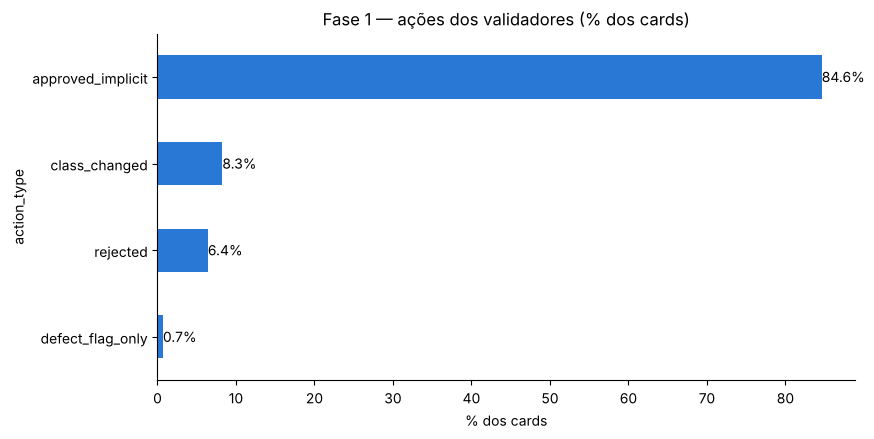

In [23]:
acoes_f1 = f1_limpo["action_type"].value_counts(normalize=True) * 100

ax = acoes_f1.sort_values().plot.barh(color=AZUL)
ax.bar_label(ax.containers[0], fmt="%.1f%%")
plt.title("Fase 1 — ações dos validadores (% dos cards)")
plt.xlabel("% dos cards")
plt.show()

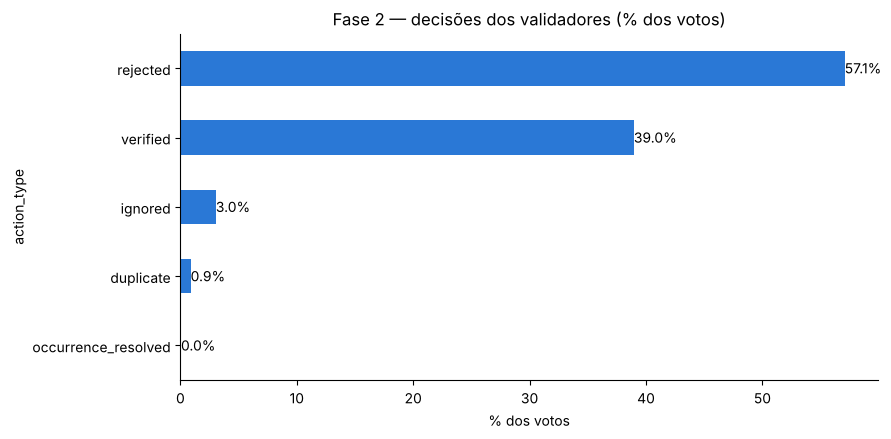

In [24]:
acoes_f2 = f2_limpo["action_type"].value_counts(normalize=True) * 100

ax = acoes_f2.sort_values().plot.barh(color=AZUL)
ax.bar_label(ax.containers[0], fmt="%.1f%%")
plt.title("Fase 2 — decisões dos validadores (% dos votos)")
plt.xlabel("% dos votos")
plt.show()

### 5.2 Rejeição por modelo de IA (Fase 2)

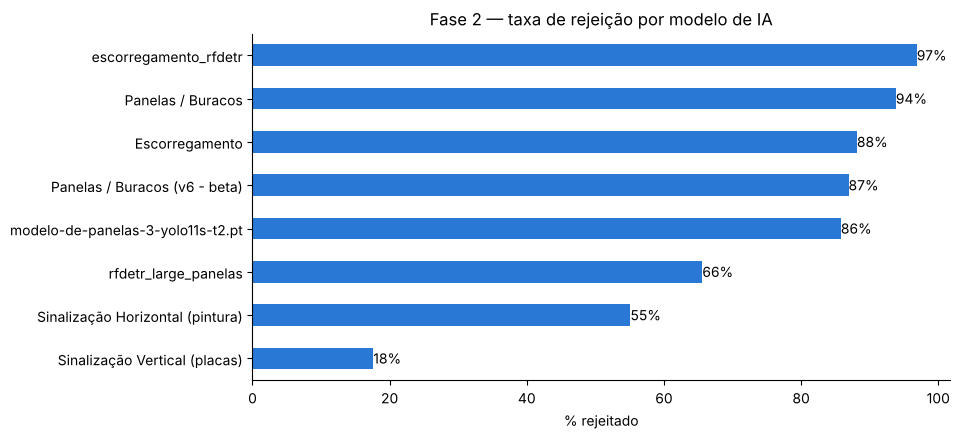

In [25]:
rejeicao_modelo = f2_limpo.groupby("inference_model_name")["rejeitado"].mean() * 100

ax = rejeicao_modelo.sort_values().plot.barh(color=AZUL)
ax.bar_label(ax.containers[0], fmt="%.0f%%")
plt.title("Fase 2 — taxa de rejeição por modelo de IA")
plt.xlabel("% rejeitado")
plt.ylabel("")
plt.show()

### 5.3 Quando o trabalho acontece

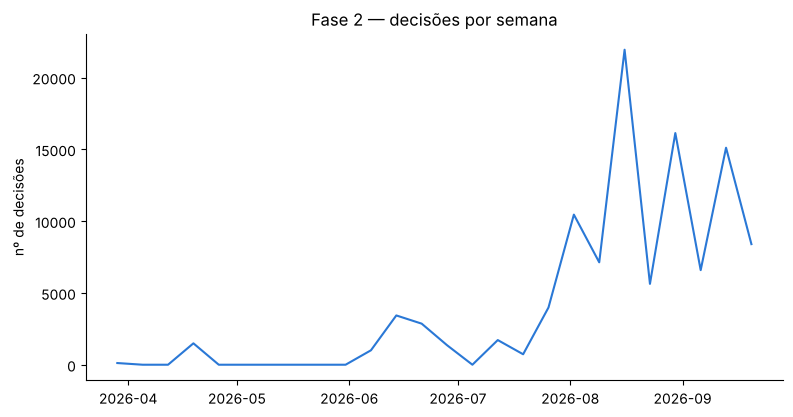

In [26]:
por_semana = f2_limpo.set_index("action_timestamp").resample("W")["action_id"].count()

plt.plot(por_semana.index, por_semana.values, color=AZUL)
plt.title("Fase 2 — decisões por semana")
plt.ylabel("nº de decisões")
plt.show()

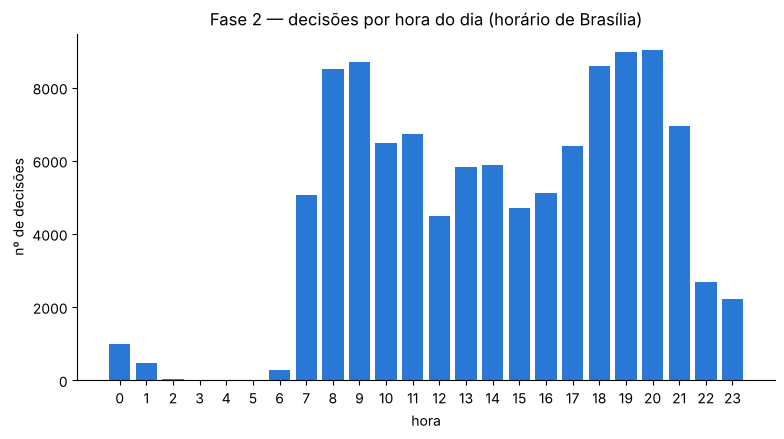

In [27]:
por_hora = f2_limpo["hora"].value_counts().sort_index()

plt.bar(por_hora.index, por_hora.values, color=AZUL)
plt.xticks(range(0, 24))
plt.title("Fase 2 — decisões por hora do dia (horário de Brasília)")
plt.xlabel("hora")
plt.ylabel("nº de decisões")
plt.show()

## 6. Caminho 1 — Em quais classes a IA mais erra?
Usamos a **Fase 1, modelo de placas**, sem os cards rejeitados (neles ninguém informa a classe certa).

In [28]:
placas = f1_limpo[f1_limpo["inference_model_name"] == "Sinalização Vertical (placas)"]
placas = placas[placas["action_type"] != "rejected"]

print("Cards analisados:", len(placas))
print("% com classe corrigida:", round(placas["classe_corrigida"].mean() * 100, 1))

Cards analisados: 62828
% com classe corrigida: 11.8


### 6.1 Taxa de correção por classe (classes com pelo menos 200 cards)

In [29]:
por_classe = placas.groupby("classe_ia").agg(
    cards=("classe_corrigida", "count"),
    corrigidos=("classe_corrigida", "sum"),
)
por_classe["taxa_correcao_%"] = (por_classe["corrigidos"] / por_classe["cards"] * 100).round(1)

por_classe = por_classe[por_classe["cards"] >= 200]
por_classe = por_classe.sort_values("taxa_correcao_%", ascending=False)
por_classe.head(15)

,cards,corrigidos,taxa_correcao_%
classe_ia,,,
[SV] R-9,290,271,93.4
[SV] A-1b,407,374,91.9
[SV] A-24,344,256,74.4
[SV] O-FE,1236,839,67.9
[SV] R-27,700,379,54.1
[SV] A-36,254,122,48.0
[SV] A-21c,222,87,39.2
[SV] A-22,233,84,36.1
[SV] I-O,9920,2899,29.2


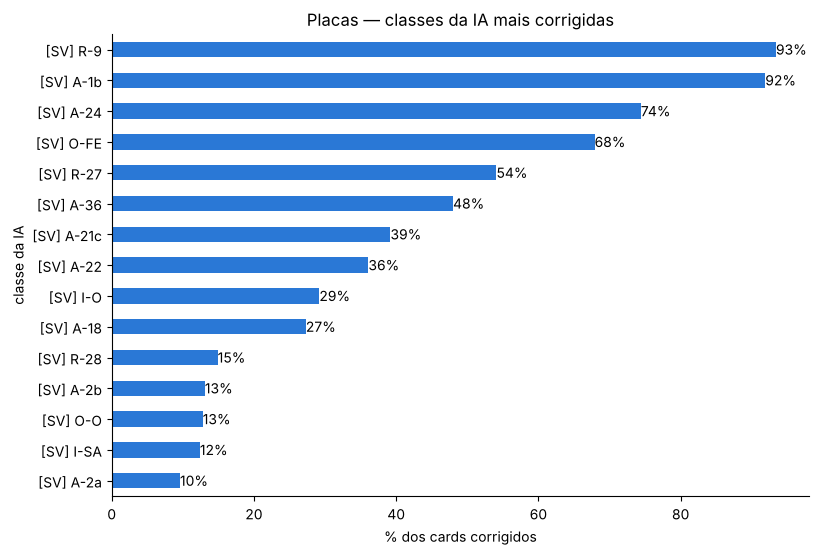

In [30]:
top15 = por_classe.head(15)["taxa_correcao_%"].sort_values()

ax = top15.plot.barh(color=AZUL, figsize=(9, 6))
ax.bar_label(ax.containers[0], fmt="%.0f%%")
plt.title("Placas — classes da IA mais corrigidas")
plt.xlabel("% dos cards corrigidos")
plt.ylabel("classe da IA")
plt.show()

### 6.2 Matriz de confusão (12 classes mais frequentes)

In [31]:
classes_top = placas["classe_ia"].value_counts().head(12).index

amostra = placas[placas["classe_ia"].isin(classes_top)].copy()

# Classes finais fora do top 12 viram "outras"
amostra["classe_final"] = amostra["taxonomy_class"]
amostra.loc[~amostra["classe_final"].isin(classes_top), "classe_final"] = "outras"

# Cada linha soma 100%
matriz = pd.crosstab(amostra["classe_ia"], amostra["classe_final"], normalize="index") * 100
matriz

classe_final,[SV] I-IK,[SV] I-O,[SV] I-SA,[SV] I-SA26,[SV] O-FE,[SV] O-MA,[SV] O-MP,[SV] R-1,[SV] R-19,[SV] R-2,[SV] R-24a,[SV] R-7,outras
classe_ia,,,,,,,,,,,,,
[SV] I-IK,98.013836,0.691810,0.200848,0.066949,0.000000,0.022316,0.000000,0.000000,0.044633,0.022316,0.000000,0.000000,0.937291
[SV] I-O,1.330645,70.776210,1.028226,0.070565,0.806452,0.000000,0.010081,0.000000,0.000000,0.000000,0.000000,0.000000,25.977823
[SV] I-SA,0.091158,2.005469,87.602552,0.000000,3.372835,0.000000,0.000000,0.000000,0.182315,0.000000,0.000000,0.000000,6.745670
[SV] I-SA26,0.060277,0.000000,0.000000,98.975286,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.964436
[SV] O-FE,0.080906,2.103560,0.809061,0.000000,32.119741,0.000000,0.000000,0.000000,0.242718,0.000000,0.000000,0.000000,64.644013
[SV] O-MA,0.000000,0.000000,0.000000,0.000000,0.000000,99.446127,0.553873,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
[SV] O-MP,0.000000,0.000000,0.000000,0.000000,0.000000,0.033300,99.933400,0.000000,0.000000,0.011100,0.000000,0.000000,0.022200
[SV] R-1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,96.345708,0.000000,0.000000,3.364269,0.000000,0.290023
[SV] R-19,0.124275,0.683513,0.062138,0.000000,0.186413,0.000000,0.000000,0.000000,96.209611,0.000000,0.124275,0.000000,2.609776


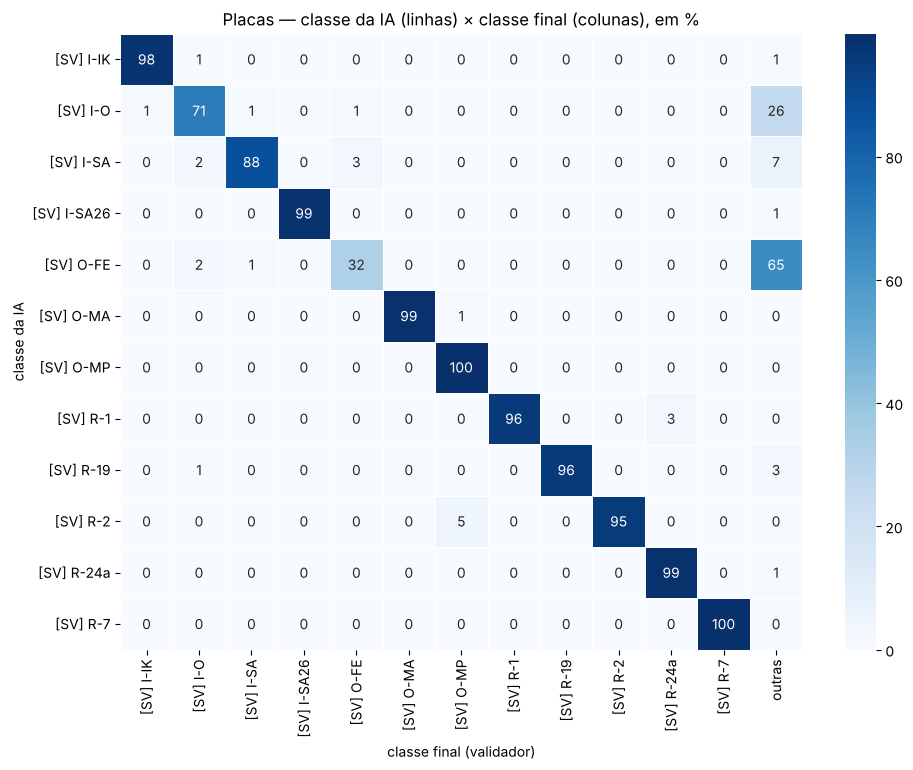

In [32]:
plt.figure(figsize=(11, 8))
sns.heatmap(matriz, cmap="Blues", annot=True, fmt=".0f", linewidths=0.5)
plt.title("Placas — classe da IA (linhas) × classe final (colunas), em %")
plt.xlabel("classe final (validador)")
plt.ylabel("classe da IA")
plt.show()

### 6.3 Trocas mais comuns

In [33]:
corrigidos = placas[placas["classe_corrigida"] == True]

trocas = corrigidos.groupby(["classe_ia", "taxonomy_class"]).size()
trocas = trocas.sort_values(ascending=False).head(15)
trocas

classe_ia  taxonomy_class
[SV] I-O   [SV] I-E          1384
[SV] O-FE  [SV] I-E           751
[SV] I-O   [SV] I-I           549
           [SV] O-O           439
[SV] R-9   [SV] R-7           267
[SV] R-27  [SV] I-E           254
[SV] A-24  [SV] O-OA24        158
[SV] I-O   [SV] I-IK          132
[SV] A-1b  [SV] A-32a         127
[SV] I-O   [SV] I-SA          102
[SV] O-O   [SV] I-O            91
[SV] I-O   [SV] T-I            91
           [SV] O-FE           80
[SV] R-19  [SV] I-E            76
[SV] O-MA  [SV] O-MP           64
dtype: int64

### Para onde vão as correções? (a classe I-E)
O Rafael explicou que I-O é uma classe "de dúvida" e que muitas placas viram I-E (educativas). Vamos medir isso.

In [34]:
# Destino das correções: qual classe o validador colocou?
destino_ie = corrigidos["taxonomy_class"] == "[SV] I-E"
print("Correções de classe em placas:", len(corrigidos))
print("Terminam em I-E:", destino_ie.sum(), "=", round(destino_ie.mean() * 100, 1), "%")

# Quantas vezes a própria IA respondeu I-E? (sem o prefixo [MISSING])
print("Vezes que a IA respondeu I-E na Fase 1:", (f1["original_class"] == "[SV] I-E").sum())
print("Vezes que a IA respondeu I-E na Fase 2:", (f2["original_class"] == "[SV] I-E").sum())

Correções de classe em placas: 7393
Terminam em I-E: 2536 = 34.3 %
Vezes que a IA respondeu I-E na Fase 1: 4
Vezes que a IA respondeu I-E na Fase 2: 0


A IA quase nunca responde I-E, mas uma parte grande das correções termina em I-E. Ou seja: as placas educativas estão sendo classificadas como outra coisa (principalmente I-O e O-FE).

### 6.4 Corrigir a classe leva mais tempo?

In [35]:
tempo_por_acao = f1_tempo.groupby("action_type")["tempo_seg"].median().round(1)
tempo_por_acao

action_type
class_changed       7.9
defect_flag_only    9.3
rejected            2.6
Name: tempo_seg, dtype: float64

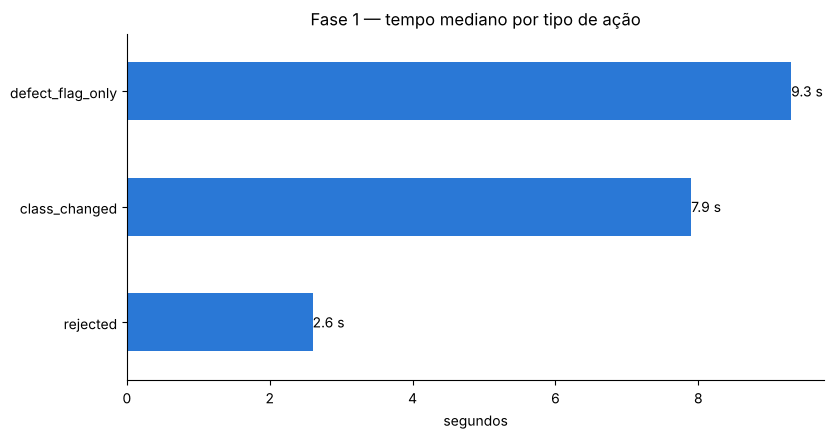

Corrigir a classe leva cerca de 3.0 vezes o tempo de rejeitar.


In [36]:
ax = tempo_por_acao.sort_values().plot.barh(color=AZUL)
ax.bar_label(ax.containers[0], fmt="%.1f s")
plt.title("Fase 1 — tempo mediano por tipo de ação")
plt.xlabel("segundos")
plt.ylabel("")
plt.show()

vezes = tempo_por_acao["class_changed"] / tempo_por_acao["rejected"]
print(f"Corrigir a classe leva cerca de {vezes:.1f} vezes o tempo de rejeitar.")

### 6.5 Em quais classes vai o tempo de correção?

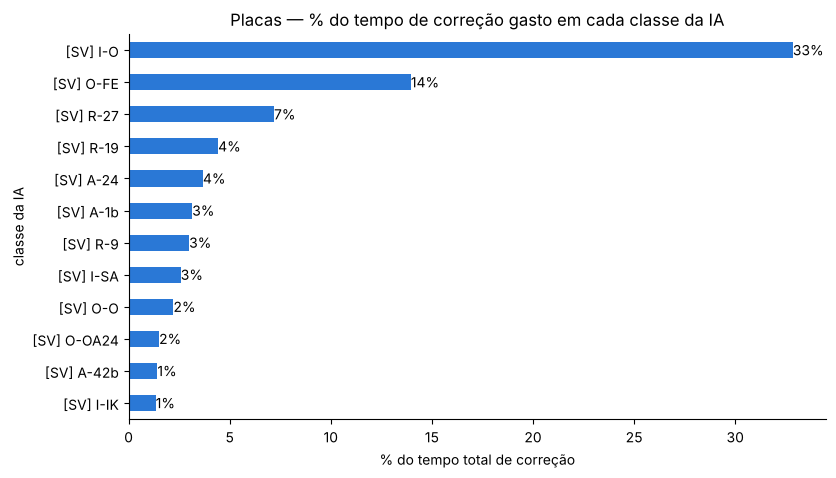

As 3 primeiras somam: 54.0 %
As 5 primeiras somam: 62.1 %


In [37]:
correcoes = f1_tempo[f1_tempo["action_type"] == "class_changed"]
correcoes = correcoes[correcoes["inference_model_name"] == "Sinalização Vertical (placas)"]

tempo_por_classe = correcoes.groupby("classe_ia")["tempo_seg"].sum()
parcela = tempo_por_classe / tempo_por_classe.sum() * 100
parcela = parcela.sort_values(ascending=False)

ax = parcela.head(12).sort_values().plot.barh(color=AZUL, figsize=(9, 5))
ax.bar_label(ax.containers[0], fmt="%.0f%%")
plt.title("Placas — % do tempo de correção gasto em cada classe da IA")
plt.xlabel("% do tempo total de correção")
plt.ylabel("classe da IA")
plt.show()

print("As 3 primeiras somam:", round(parcela.head(3).sum(), 1), "%")
print("As 5 primeiras somam:", round(parcela.head(5).sum(), 1), "%")

## 7. Caminho 2 — Comportamento dos validadores
Não existe gabarito: medimos **comportamento**, não acerto. Comparamos dentro do **mesmo modelo (placas)** e só validadores com **pelo menos 500 cards**.

### 7.1 Taxa de intervenção (Fase 1, placas)

In [38]:
placas_f1 = f1_limpo[f1_limpo["inference_model_name"] == "Sinalização Vertical (placas)"]

intervencao = placas_f1.groupby("validator_id").agg(
    cards=("intervencao", "count"),
    taxa_intervencao=("intervencao", "mean"),
    taxa_correcao=("classe_corrigida", "mean"),
)
intervencao = intervencao[intervencao["cards"] >= 500]
intervencao["taxa_intervencao"] = (intervencao["taxa_intervencao"] * 100).round(1)
intervencao["taxa_correcao"] = (intervencao["taxa_correcao"] * 100).round(1)
intervencao = intervencao.sort_values("taxa_intervencao")
intervencao

,cards,taxa_intervencao,taxa_correcao
validator_id,,,
CC6EB2,3074,10.1,6.3
38BB7D,3183,12.8,4.5
75108A,6926,13.2,5.3
85EB1D,1914,14.3,6.1
A242B0,710,15.6,4.6
9A81CF,40974,20.9,12.3
9F8E8E,11394,24.5,13.1


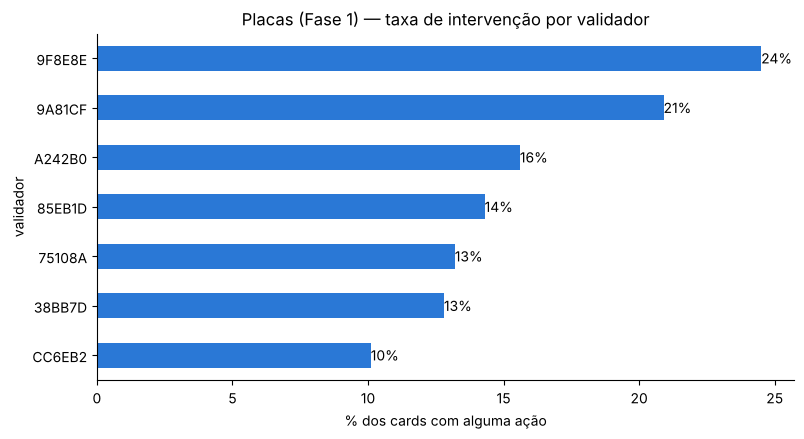

In [39]:
ax = intervencao["taxa_intervencao"].plot.barh(color=AZUL)
ax.bar_label(ax.containers[0], fmt="%.0f%%")
plt.title("Placas (Fase 1) — taxa de intervenção por validador")
plt.xlabel("% dos cards com alguma ação")
plt.ylabel("validador")
plt.show()

### 7.2 Quem rejeita mais demora mais? (Fase 2, placas)

In [40]:
placas_f2 = f2_limpo[f2_limpo["inference_model_name"] == "Sinalização Vertical (placas)"]

comportamento = placas_f2.groupby("validator_id").agg(
    cards=("action_id", "count"),
    taxa_rejeicao=("rejeitado", "mean"),
    tempo_mediano=("tempo_seg", "median"),
)
comportamento = comportamento[comportamento["cards"] >= 500]
comportamento["taxa_rejeicao"] = (comportamento["taxa_rejeicao"] * 100).round(1)
comportamento["tempo_mediano"] = comportamento["tempo_mediano"].round(1)
comportamento

,cards,taxa_rejeicao,tempo_mediano
validator_id,,,
38BB7D,2225,18.1,4.6
75108A,5601,19.9,2.8
85EB1D,2186,22.8,4.4
9A81CF,17195,18.9,6.5
9F8E8E,3483,13.1,12.3
A242B0,631,0.8,1.3
C54E91,610,19.3,2.7
CC6EB2,1528,3.7,2.6


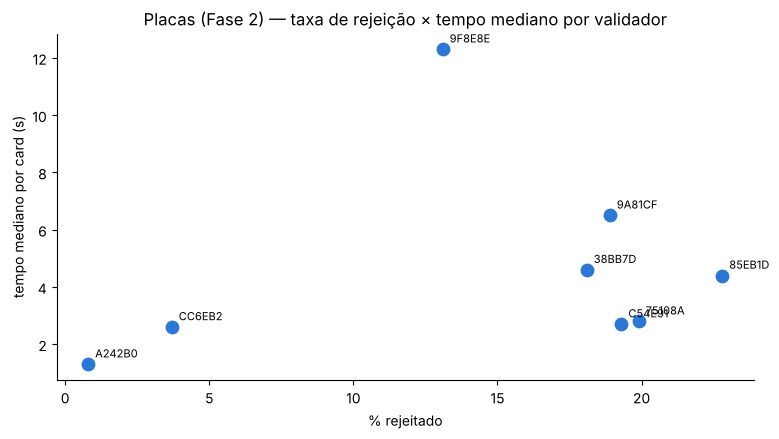

Correlação de Spearman: 0.29


In [41]:
plt.scatter(comportamento["taxa_rejeicao"], comportamento["tempo_mediano"], s=80, color=AZUL)

# Escrever o nome de cada validador ao lado do ponto
for validador in comportamento.index:
    x = comportamento.loc[validador, "taxa_rejeicao"]
    y = comportamento.loc[validador, "tempo_mediano"]
    plt.annotate(validador, (x, y), xytext=(5, 5), textcoords="offset points", fontsize=8)

plt.title("Placas (Fase 2) — taxa de rejeição × tempo mediano por validador")
plt.xlabel("% rejeitado")
plt.ylabel("tempo mediano por card (s)")
plt.show()

correlacao = comportamento["taxa_rejeicao"].corr(comportamento["tempo_mediano"], method="spearman")
print("Correlação de Spearman:", round(correlacao, 2))

### Validadores fora do padrão
O Rafael disse que não existe uma taxa "certa", mas que vale olhar quem está **muito diferente dos demais**. Regra simples que usamos: abaixo da **metade** ou acima do **dobro** da mediana do grupo.

In [42]:
mediana = comportamento["taxa_rejeicao"].median()
comportamento["fora_do_padrao"] = (comportamento["taxa_rejeicao"] < mediana / 2) | (comportamento["taxa_rejeicao"] > mediana * 2)

print("Mediana da taxa de rejeição (placas, Fase 2):", mediana, "%")
comportamento.sort_values("taxa_rejeicao")

Mediana da taxa de rejeição (placas, Fase 2): 18.5 %


,cards,taxa_rejeicao,tempo_mediano,fora_do_padrao
validator_id,,,,
A242B0,631,0.8,1.3,True
CC6EB2,1528,3.7,2.6,True
9F8E8E,3483,13.1,12.3,False
38BB7D,2225,18.1,4.6,False
9A81CF,17195,18.9,6.5,False
C54E91,610,19.3,2.7,False
75108A,5601,19.9,2.8,False
85EB1D,2186,22.8,4.4,False


In [43]:
# A mesma regra na taxa de intervenção da Fase 1
mediana_f1 = intervencao["taxa_intervencao"].median()
intervencao["fora_do_padrao"] = (intervencao["taxa_intervencao"] < mediana_f1 / 2) | (intervencao["taxa_intervencao"] > mediana_f1 * 2)
print("Mediana da taxa de intervenção (placas, Fase 1):", mediana_f1, "%")
intervencao

Mediana da taxa de intervenção (placas, Fase 1): 14.3 %


,cards,taxa_intervencao,taxa_correcao,fora_do_padrao
validator_id,,,,
CC6EB2,3074,10.1,6.3,False
38BB7D,3183,12.8,4.5,False
75108A,6926,13.2,5.3,False
85EB1D,1914,14.3,6.1,False
A242B0,710,15.6,4.6,False
9A81CF,40974,20.9,12.3,False
9F8E8E,11394,24.5,13.1,False


### 7.3 Curva de aprendizado (Fase 2)

In [44]:
# Semana de experiência = semanas desde a primeira decisão do validador
primeira_decisao = f2_limpo.groupby("validator_id")["action_timestamp"].transform("min")
f2_limpo["semana_exp"] = (f2_limpo["action_timestamp"] - primeira_decisao).dt.days // 7

# Tempo mediano por semana (linhas) e validador (colunas)
curva = f2_limpo.pivot_table(index="semana_exp", columns="validator_id",
                             values="tempo_seg", aggfunc="median")

# Quantos cards em cada semana — semanas com menos de 50 cards ficam de fora
cards_semana = f2_limpo.pivot_table(index="semana_exp", columns="validator_id",
                                    values="action_id", aggfunc="count")
curva = curva[cards_semana >= 50]

# Só validadores com pelo menos 4 semanas de dados
curva = curva.loc[:, curva.notna().sum() >= 4]
curva.round(1)

validator_id,75108A,85EB1D,9A81CF,9F8E8E,CC6EB2
semana_exp,,,,,
0,5.6,NaN,5.5,18.8,3.7
1,NaN,NaN,8.5,15.8,3.0
2,2.4,NaN,7.2,12.8,NaN
3,NaN,NaN,6.0,NaN,NaN
4,NaN,NaN,12.5,2.5,NaN
5,NaN,2.3,12.9,39.2,NaN
6,NaN,8.4,3.0,NaN,2.2
7,NaN,NaN,NaN,NaN,2.4
8,NaN,4.9,NaN,NaN,2.8


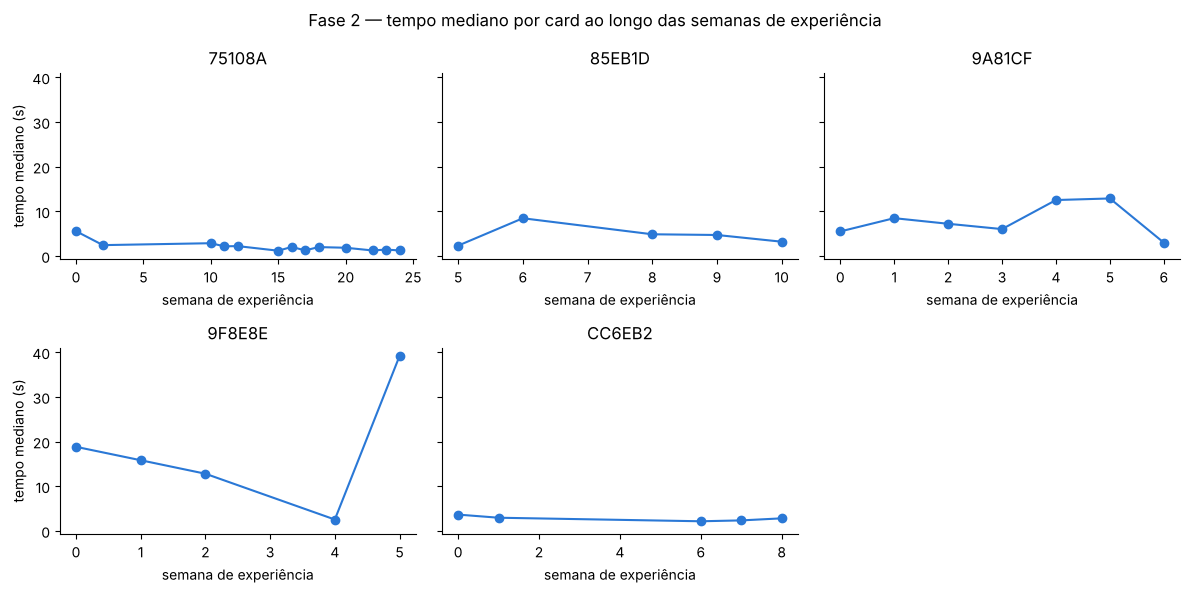

In [45]:
# Um gráfico pequeno para cada validador (2 linhas x 3 colunas)
fig, eixos = plt.subplots(2, 3, figsize=(12, 6), sharey=True)
eixos = eixos.flatten()

for i, validador in enumerate(curva.columns):
    dados = curva[validador].dropna()   # só as semanas com dados
    eixos[i].plot(dados.index, dados.values, marker="o", color=AZUL)
    eixos[i].set_title(validador)
    eixos[i].set_xlabel("semana de experiência")

# Esconder os quadros que sobraram
for j in range(len(curva.columns), len(eixos)):
    eixos[j].set_visible(False)

eixos[0].set_ylabel("tempo mediano (s)")
eixos[3].set_ylabel("tempo mediano (s)")
plt.suptitle("Fase 2 — tempo mediano por card ao longo das semanas de experiência")
plt.tight_layout()
plt.show()

## 8. Diagnóstico — quanto tempo daria para economizar?
Pergunta de negócio: *quais classes concentram o tempo de correção e quanto tempo a Visior economizaria melhorando-as?*

Ideia do cálculo: somamos o tempo estimado de todas as correções de classe do modelo de placas. Depois imaginamos cenários em que a IA passa a errar **menos** nas 3 classes que mais pesam (I-O, O-FE e R-27). Cada correção que deixa de existir é tempo que o validador economiza.

In [46]:
# Correções de classe no modelo de placas, com tempo medido (Fase 1)
correcoes = f1_tempo[f1_tempo["action_type"] == "class_changed"]
correcoes = correcoes[correcoes["inference_model_name"] == "Sinalização Vertical (placas)"]

horas_total = correcoes["tempo_seg"].sum() / 3600

top3 = ["[SV] I-O", "[SV] O-FE", "[SV] R-27"]
correcoes_top3 = correcoes[correcoes["classe_ia"].isin(top3)]
horas_top3 = correcoes_top3["tempo_seg"].sum() / 3600

print("Horas gastas corrigindo classe (placas):", round(horas_total, 1))
print("Horas gastas nas 3 classes principais:  ", round(horas_top3, 1))
print("Participação das 3 classes:", round(horas_top3 / horas_total * 100), "%")

Horas gastas corrigindo classe (placas): 24.4
Horas gastas nas 3 classes principais:   13.2
Participação das 3 classes: 54 %


In [47]:
# Cenários: a IA erra 25%, 50% ou 75% menos nessas 3 classes
cenarios = []
for reducao in [0.25, 0.50, 0.75]:
    cenarios.append({
        "redução do erro": f"{int(reducao * 100)}%",
        "correções evitadas": int(len(correcoes_top3) * reducao),
        "horas economizadas": round(horas_top3 * reducao, 1),
    })

cenarios = pd.DataFrame(cenarios)
cenarios

,redução do erro,correções evitadas,horas economizadas
0,25%,1011,3.3
1,50%,2023,6.6
2,75%,3035,9.9


In [48]:
# Quanto isso representa do tempo de ação dos validadores em placas?
placas_tempo = f1_tempo[f1_tempo["inference_model_name"] == "Sinalização Vertical (placas)"]
horas_acoes_placas = placas_tempo["tempo_seg"].sum() / 3600

economia_50 = horas_top3 * 0.5
print("Tempo total de ações em placas (h):", round(horas_acoes_placas, 1))
print("Economia no cenário de 50% (h):    ", round(economia_50, 1))
print("Isso é", round(economia_50 / horas_acoes_placas * 100), "% do tempo de ação em placas")

Tempo total de ações em placas (h): 36.4
Economia no cenário de 50% (h):     6.6
Isso é 18 % do tempo de ação em placas


In [49]:
# Projeção mensal no ritmo recente (agosto e setembro)
placas_f1 = f1_limpo[f1_limpo["inference_model_name"] == "Sinalização Vertical (placas)"]
cards_placas = len(placas_f1)

# minutos economizados a cada 1.000 cards de placas
min_por_mil = economia_50 * 60 / cards_placas * 1000

recente = placas_f1[placas_f1["action_timestamp"] >= "2026-08-01"]
meses = (recente["action_timestamp"].max() - recente["action_timestamp"].min()).days / 30.44
cards_por_mes = len(recente) / meses

print("Cards de placas por mês (ago-set):", round(cards_por_mes))
print("Economia a cada 1.000 cards (min):", round(min_por_mil, 1))
print("Economia por mês nesse ritmo (h): ", round(min_por_mil * cards_por_mes / 1000 / 60, 1))

Cards de placas por mês (ago-set): 40618
Economia a cada 1.000 cards (min): 5.8
Economia por mês nesse ritmo (h):  3.9


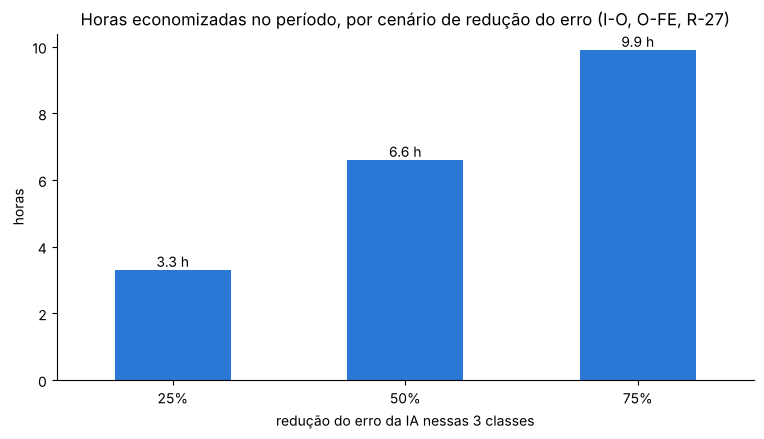

In [50]:
ax = cenarios.plot.bar(x="redução do erro", y="horas economizadas", color=AZUL, legend=False, rot=0)
ax.bar_label(ax.containers[0], fmt="%.1f h")
plt.title("Horas economizadas no período, por cenário de redução do erro (I-O, O-FE, R-27)")
plt.xlabel("redução do erro da IA nessas 3 classes")
plt.ylabel("horas")
plt.show()

**Cuidado ao interpretar:** o tempo é estimado pelo intervalo entre decisões, então mostra só o tempo de clique, não o tempo total olhando o mosaico. Por isso, as horas reais tendem a ser **maiores**. O cenário também supõe que um card que a IA acerta passa sem ação, sem custo extra.

## 9. Próximo passo
Os resultados acima estão interpretados no documento **Conclusões da Análise Exploratória**, com o porquê de cada conclusão e as limitações dos dados.